# MSCS 634: Data Mining and Machine Learning
## Lab 4: Regression and Regularization

**Name:** Nikita Metha  
**Course:** MSCS 634: Data Mining and Machine Learning  
**Assignment:** Regression Analysis with Regularization Techniques

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

RANDOM_STATE = 42  # same as previous labs
TEST_SIZE = 0.20
pd.set_option('display.max_columns', None)

## Step 1: Load and Prepare the Dataset

In [17]:
# load Diabetes dataset
diabetes = load_diabetes(as_frame=True)
X = diabetes.data.copy()  # independent variables/features
y = diabetes.target.copy()  # target/dependent variable

# basic data exploration for features and data distribution.
print(f'Samples: {X.shape[0]}')
print(f'Features: {X.shape[1]}')
print('Feature names:', list(X.columns))
print('\nFirst few target values:')
display(y.head(10).to_frame('target'))
print('\nMissing values by feature:')
display(X.isna().sum())
print(f'Total missing feature values: {X.isna().sum().sum()}')
print(f'Missing target values: {y.isna().sum()}')

# remove rows with missing values if any are there
valid_rows = X.notna().all(axis=1) & y.notna()
X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].copy()
print(f'Rows after cleaning: {X.shape[0]}')

display(X.describe().T)
display(y.describe().to_frame('target'))

Samples: 442
Features: 10
Feature names: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

First few target values:


,target
0,151.0
1,75.0
2,141.0
3,206.0
4,135.0
5,97.0
6,138.0
7,63.0
8,110.0
9,310.0



Missing values by feature:


age    0
sex    0
bmi    0
bp     0
s1     0
s2     0
s3     0
s4     0
s5     0
s6     0
dtype: int64

Total missing feature values: 0
Missing target values: 0
Rows after cleaning: 442


,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.293722e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612


,target
count,442.000000
mean,152.133484
std,77.093005
min,25.000000
25%,87.000000
50%,140.500000
75%,211.500000
max,346.000000


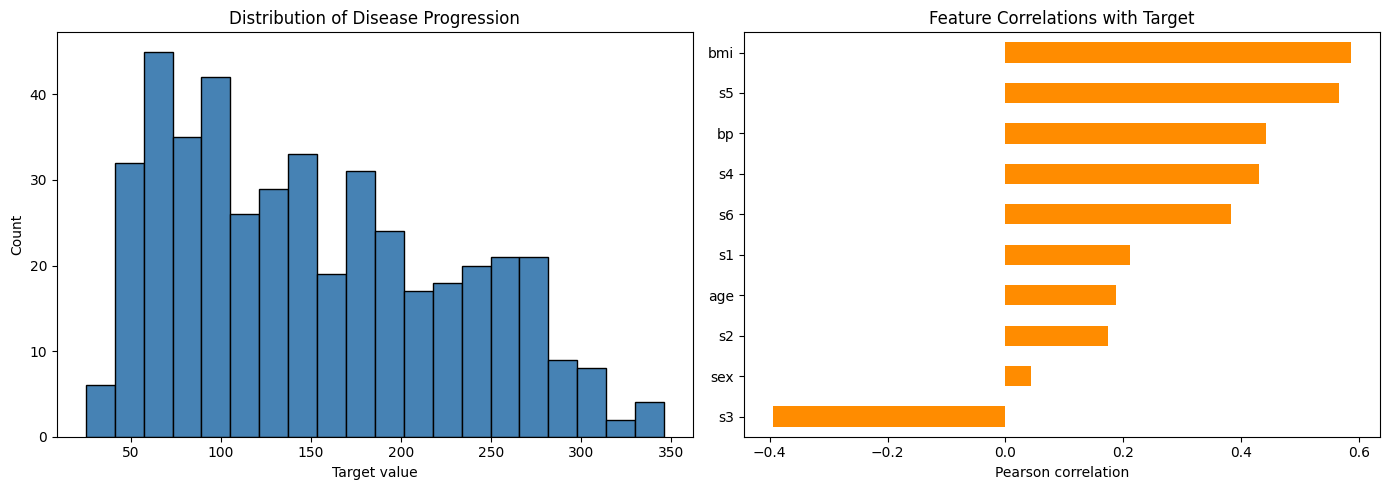

In [3]:
# make plots for target distribution and feature correlations - data exploration
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(y, bins=20, edgecolor='black', color='steelblue')
axes[0].set_title('Distribution of Disease Progression')
axes[0].set_xlabel('Target value')
axes[0].set_ylabel('Count')

correlations = X.assign(target=y).corr()['target'].drop('target').sort_values()
correlations.plot(kind='barh', ax=axes[1], color='darkorange')
axes[1].set_title('Feature Correlations with Target')
axes[1].set_xlabel('Pearson correlation')
plt.tight_layout()
plt.show()

In [4]:
# function to train the model and calculate the metrics
def evaluate_model(model, X_train_data, X_test_data, y_train_data, y_test_data):
    model.fit(X_train_data, y_train_data)
    train_predictions = model.predict(X_train_data)
    test_predictions = model.predict(X_test_data)
    return {
        'MAE': mean_absolute_error(y_test_data, test_predictions),
        'MSE': mean_squared_error(y_test_data, test_predictions),
        'RMSE': np.sqrt(mean_squared_error(y_test_data, test_predictions)),
        'R2': r2_score(y_test_data, test_predictions),
        'Train R2': r2_score(y_train_data, train_predictions),
        'predictions': test_predictions,
        'fitted_model': model
    }

def metrics_only(evaluation):
    return {metric: evaluation[metric] for metric in ['MAE', 'MSE', 'RMSE', 'R2']}

## Step 2: Simple Linear Regression

In [5]:
# split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

# select the feature using training data only to avoid test-target leakage
train_correlations = X_train.assign(target=y_train).corr()['target'].drop('target')
simple_feature = train_correlations.abs().idxmax()
print(f'Selected feature from training data: {simple_feature}')

simple_model = LinearRegression()
simple_evaluation = evaluate_model(
    simple_model, X_train[[simple_feature]], X_test[[simple_feature]], y_train, y_test
)
display(pd.Series(metrics_only(simple_evaluation), name='Simple Linear Regression').to_frame())

Selected feature from training data: bmi


,Simple Linear Regression
MAE,52.259976
MSE,4061.825928
RMSE,63.732456
R2,0.233350


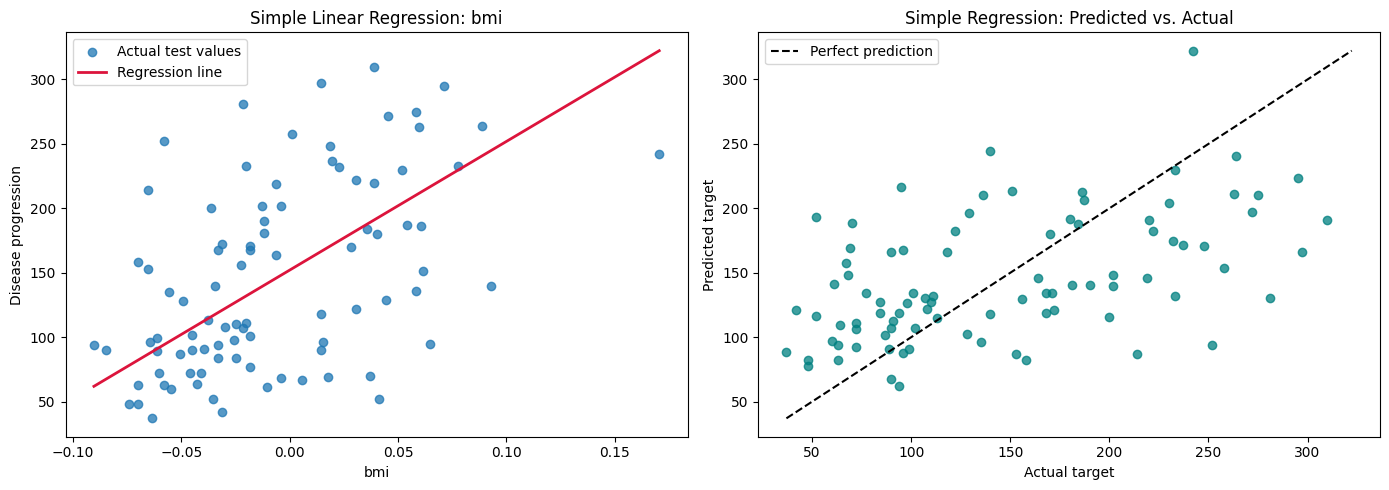

In [6]:
# plot the actual values and predicted values for the simple model
sorted_test = X_test[[simple_feature]].assign(actual=y_test).sort_values(simple_feature)
line_predictions = simple_evaluation['fitted_model'].predict(sorted_test[[simple_feature]])
simple_predictions = simple_evaluation['predictions']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(X_test[simple_feature], y_test, alpha=0.75, label='Actual test values')
axes[0].plot(sorted_test[simple_feature], line_predictions, color='crimson', linewidth=2, label='Regression line')
axes[0].set_title(f'Simple Linear Regression: {simple_feature}')
axes[0].set_xlabel(simple_feature)
axes[0].set_ylabel('Disease progression')
axes[0].legend()

axes[1].scatter(y_test, simple_predictions, alpha=0.75, color='teal')
simple_limits = [min(y_test.min(), simple_predictions.min()), max(y_test.max(), simple_predictions.max())]
axes[1].plot(simple_limits, simple_limits, '--', color='black', label='Perfect prediction')
axes[1].set_title('Simple Regression: Predicted vs. Actual')
axes[1].set_xlabel('Actual target')
axes[1].set_ylabel('Predicted target')
axes[1].legend()

plt.tight_layout()
plt.show()

## Step 3: Multiple Linear Regression

In [7]:
# use all the features for multiple regression
multiple_model = Pipeline([
    ('scaler', StandardScaler()),
    ('regressor', LinearRegression())
])
multiple_evaluation = evaluate_model(
    multiple_model, X_train, X_test, y_train, y_test
)
# check the model with the same metrics as before
display(pd.Series(metrics_only(multiple_evaluation), name='Multiple Linear Regression').to_frame())

,Multiple Linear Regression
MAE,42.794095
MSE,2900.193628
RMSE,53.853446
R2,0.452603


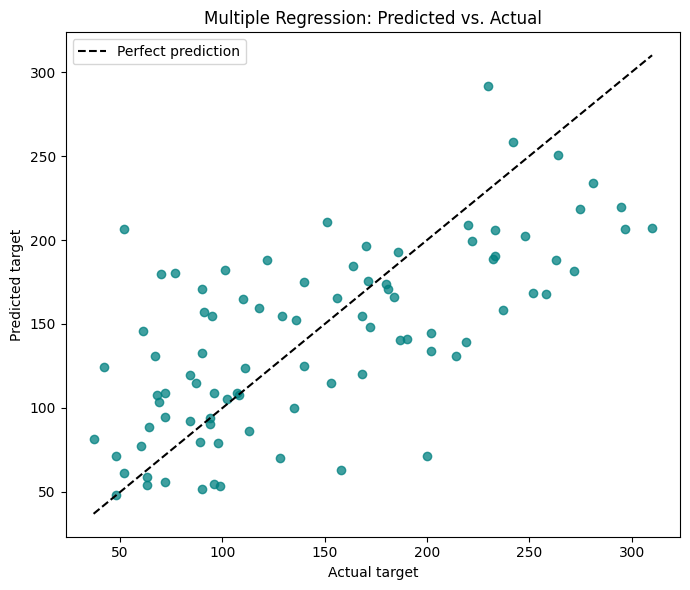

In [8]:
# plot predicted values vs actual values
plt.figure(figsize=(7, 6))
plt.scatter(y_test, multiple_evaluation['predictions'], alpha=0.75, color='teal')
plot_limits = [min(y_test.min(), multiple_evaluation['predictions'].min()), max(y_test.max(), multiple_evaluation['predictions'].max())]
plt.plot(plot_limits, plot_limits, '--', color='black', label='Perfect prediction')
plt.title('Multiple Regression: Predicted vs. Actual')
plt.xlabel('Actual target')
plt.ylabel('Predicted target')
plt.legend()
plt.tight_layout()
plt.show()

## Step 4: Polynomial Regression

In [9]:
# try polynomial regression with diffrent degrees to see underfitting and overfitting
polynomial_evaluations = {}
polynomial_rows = []
for degree in [1, 2, 3]:
    polynomial_model = Pipeline([
        ('polynomial_features', PolynomialFeatures(degree=degree, include_bias=False)),
        ('scaler', StandardScaler()),
        ('regressor', LinearRegression())
    ])
    evaluation = evaluate_model(polynomial_model, X_train, X_test, y_train, y_test)
    polynomial_evaluations[degree] = evaluation
    # save the train and test results so we can compare the degree
    polynomial_rows.append({
        'Degree': degree,
        'Train R2': evaluation['Train R2'],
        'Test MAE': evaluation['MAE'],
        'Test RMSE': evaluation['RMSE'],
        'Test R2': evaluation['R2']
    })

polynomial_comparison = pd.DataFrame(polynomial_rows).set_index('Degree')
display(polynomial_comparison.round(4))

,Train R2,Test MAE,Test RMSE,Test R2
Degree,,,,
1,0.5279,42.7941,53.8534,0.4526
2,0.6062,43.5817,55.6420,0.4156
3,0.8773,164.8539,287.1342,-14.5613


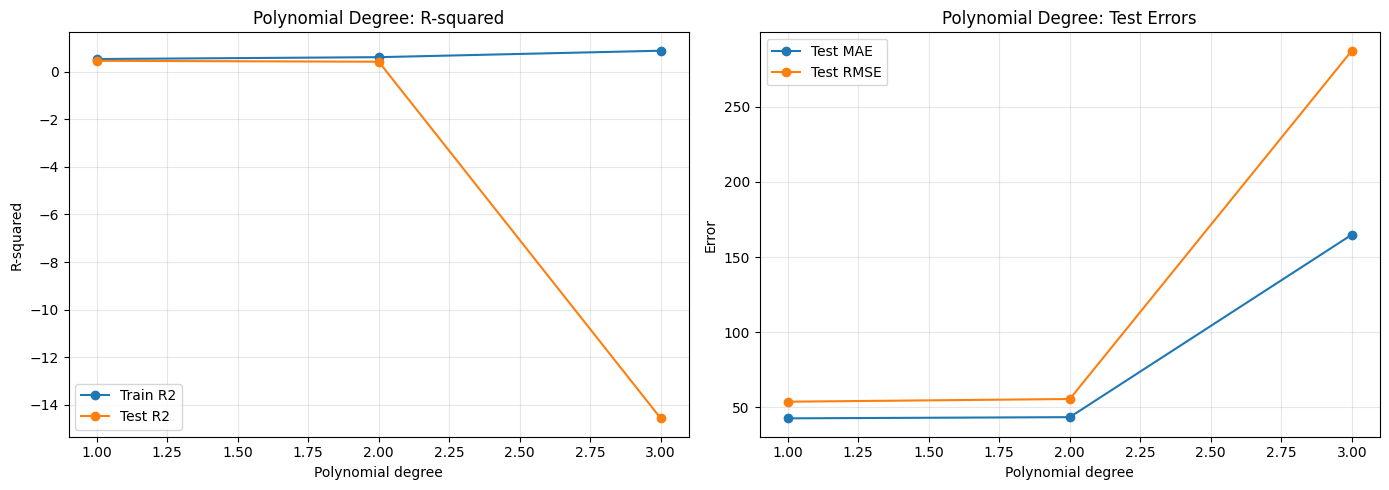

In [10]:
# compare polynomial results in plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
polynomial_comparison[['Train R2', 'Test R2']].plot(marker='o', ax=axes[0])
axes[0].set_title('Polynomial Degree: R-squared')
axes[0].set_xlabel('Polynomial degree')
axes[0].set_ylabel('R-squared')
axes[0].grid(alpha=0.3)
polynomial_comparison[['Test MAE', 'Test RMSE']].plot(marker='o', ax=axes[1])
axes[1].set_title('Polynomial Degree: Test Errors')
axes[1].set_xlabel('Polynomial degree')
axes[1].set_ylabel('Error')
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Polynomial degree interpretation

Degree 1 gives a useful baseline, while degree 2 tests whether added curvature improves generalization. Compare both training and test R-squared: a much higher training score paired with weaker test metrics indicates overfitting. Here, the degree-3 model's much worse test results show that added complexity does not necessarily improve predictions.

## Step 5: Ridge and Lasso Regression

In [11]:
# compare Ridge and Lasso alpha values using cross-validation on training data only
alphas = np.logspace(-3, 3, 13)
scoring = {'RMSE': 'neg_root_mean_squared_error', 'R2': 'r2'}

ridge_search = GridSearchCV(
    Pipeline([
        ('scaler', StandardScaler()),
        ('regressor', Ridge())
    ]),
    param_grid={'regressor__alpha': alphas},
    scoring=scoring,
    refit='RMSE',
    cv=5
 )
lasso_search = GridSearchCV(
    Pipeline([
        ('scaler', StandardScaler()),
        ('regressor', Lasso(max_iter=100000))
    ]),
    param_grid={'regressor__alpha': alphas},
    scoring=scoring,
    refit='RMSE',
    cv=5
 )

ridge_search.fit(X_train, y_train)
lasso_search.fit(X_train, y_train)

best_ridge_alpha = float(ridge_search.best_params_['regressor__alpha'])
best_lasso_alpha = float(lasso_search.best_params_['regressor__alpha'])
print(f'Best Ridge alpha by 5-fold CV RMSE: {best_ridge_alpha:g}')
print(f'Best Lasso alpha by 5-fold CV RMSE: {best_lasso_alpha:g}')

# Evaluate each selected model once on the held-out test set
ridge_evaluations = {
    best_ridge_alpha: evaluate_model(ridge_search.best_estimator_, X_train, X_test, y_train, y_test)
}
lasso_evaluations = {
    best_lasso_alpha: evaluate_model(lasso_search.best_estimator_, X_train, X_test, y_train, y_test)
}

regularization_rows = []
for model_name, search in [('Ridge', ridge_search), ('Lasso', lasso_search)]:
    cv_results = search.cv_results_
    for index, alpha in enumerate(cv_results['param_regressor__alpha']):
        regularization_rows.append({
            'Model': model_name,
            'Alpha': float(alpha),
            'CV RMSE': -cv_results['mean_test_RMSE'][index],
            'CV R2': cv_results['mean_test_R2'][index]
        })

regularization_comparison = pd.DataFrame(regularization_rows)
display(regularization_comparison.round(4))

Best Ridge alpha by 5-fold CV RMSE: 31.6228
Best Lasso alpha by 5-fold CV RMSE: 1


,Model,Alpha,CV RMSE,CV R2
0,Ridge,0.0010,55.9720,0.4493
1,Ridge,0.0032,55.9717,0.4493
2,Ridge,0.0100,55.9710,0.4493
3,Ridge,0.0316,55.9686,0.4494
4,Ridge,0.1000,55.9617,0.4496
5,Ridge,0.3162,55.9445,0.4502
6,Ridge,1.0000,55.9165,0.4513
7,Ridge,3.1623,55.8982,0.4524
8,Ridge,10.0000,55.8645,0.4539
9,Ridge,31.6228,55.8048,0.4564


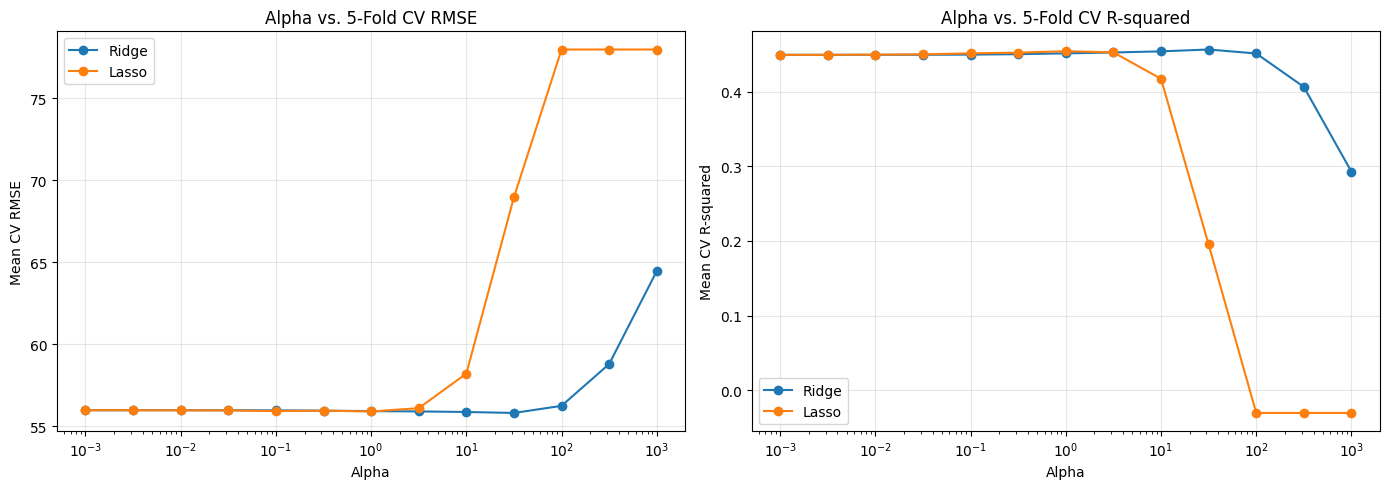

In [12]:
# plot how alpha affects cross-validated performance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for model_name, search in [('Ridge', ridge_search), ('Lasso', lasso_search)]:
    cv_results = search.cv_results_
    axes[0].plot(
        alphas, -cv_results['mean_test_RMSE'], marker='o', label=model_name
    )
    axes[1].plot(
        alphas, cv_results['mean_test_R2'], marker='o', label=model_name
    )
axes[0].set_title('Alpha vs. 5-Fold CV RMSE')
axes[1].set_title('Alpha vs. 5-Fold CV R-squared')
for axis in axes:
    axis.set_xscale('log')
    axis.set_xlabel('Alpha')
    axis.grid(alpha=0.3)
    axis.legend()
axes[0].set_ylabel('Mean CV RMSE')
axes[1].set_ylabel('Mean CV R-squared')
plt.tight_layout()
plt.show()

### Regularization interpretation

The alpha plots use five-fold cross-validation on the training set, so the held-out test set remains untouched during tuning. Increasing alpha strengthens the coefficient penalty: Ridge generally shrinks coefficients, while Lasso can shrink some to zero. A very large penalty can underfit, so choose alpha using cross-validated error and use the test metrics below only for final comparison.

,Ridge,Lasso
age,1.9906,0.6870
sex,-10.1977,-9.2975
bmi,24.5347,26.2192
bp,15.6143,15.6573
s1,-6.2817,-8.2282
s2,-3.6961,-0.0000
s3,-8.7150,-9.0241
s4,7.4106,3.4209
s5,19.5184,22.6365
s6,3.5616,2.0986


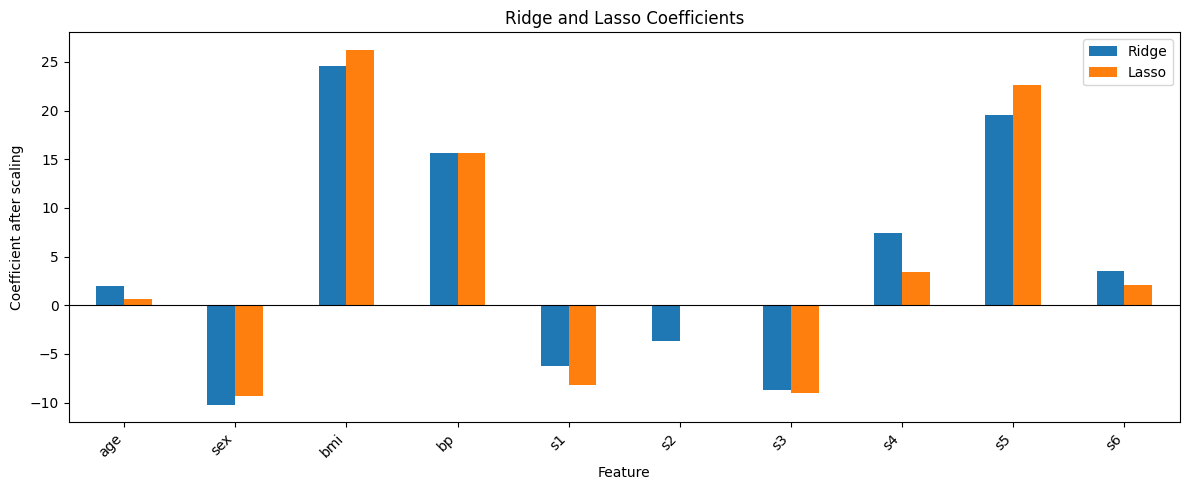

In [13]:
# compare the Ridge and Lasso coefficients
best_ridge = ridge_evaluations[best_ridge_alpha]['fitted_model']
best_lasso = lasso_evaluations[best_lasso_alpha]['fitted_model']
coefficient_comparison = pd.DataFrame({
    'Ridge': best_ridge.named_steps['regressor'].coef_,
    'Lasso': best_lasso.named_steps['regressor'].coef_
}, index=X.columns)
display(coefficient_comparison.round(4))

coefficient_comparison.plot(kind='bar', figsize=(12, 5))
plt.title('Ridge and Lasso Coefficients')
plt.xlabel('Feature')
plt.ylabel('Coefficient after scaling')
plt.xticks(rotation=45, ha='right')
plt.axhline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

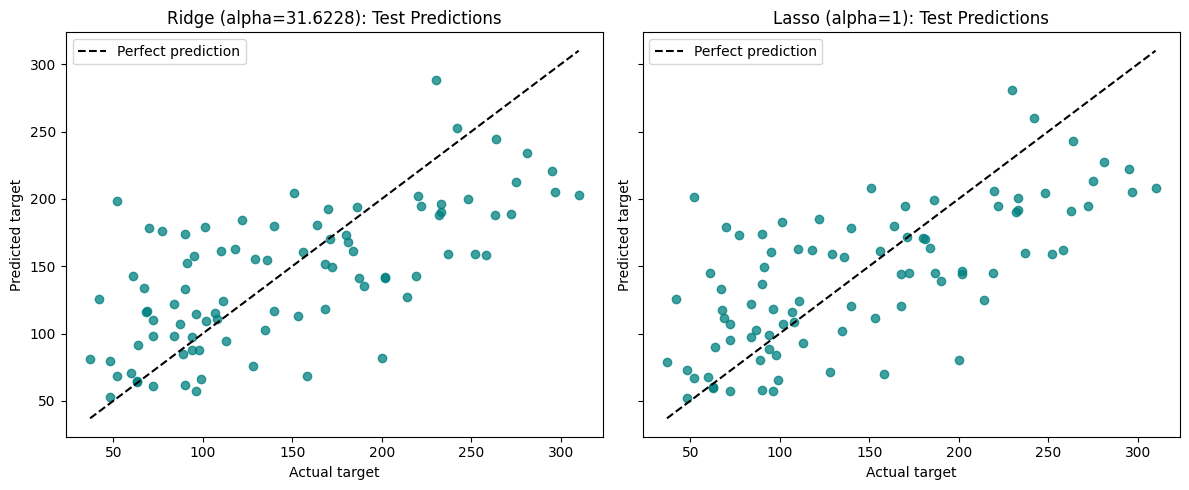

In [14]:
# compare held-out predictions from the selected Ridge and Lasso models
ridge_test_predictions = ridge_evaluations[best_ridge_alpha]['predictions']
lasso_test_predictions = lasso_evaluations[best_lasso_alpha]['predictions']
prediction_limits = [
    min(y_test.min(), ridge_test_predictions.min(), lasso_test_predictions.min()),
    max(y_test.max(), ridge_test_predictions.max(), lasso_test_predictions.max())
]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for axis, model_name, predictions in [
    (axes[0], f'Ridge (alpha={best_ridge_alpha:g})', ridge_test_predictions),
    (axes[1], f'Lasso (alpha={best_lasso_alpha:g})', lasso_test_predictions)
 ]:
    axis.scatter(y_test, predictions, alpha=0.75, color='teal')
    axis.plot(prediction_limits, prediction_limits, '--', color='black', label='Perfect prediction')
    axis.set_title(f'{model_name}: Test Predictions')
    axis.set_xlabel('Actual target')
    axis.set_ylabel('Predicted target')
    axis.legend()

plt.tight_layout()
plt.show()

### Reading the prediction plots

Points closer to the dashed diagonal have smaller prediction errors. Compare Ridge and Lasso on the same held-out observations, alongside their MAE, MSE, RMSE, and R-squared values; no single metric captures every aspect of model performance.

## Step 6: Model Comparison and Analysis

In [15]:
# make one table to compare the main models
primary_models = {
    'Simple Linear': simple_evaluation,
    'Multiple Linear': multiple_evaluation,
    'Polynomial (degree 2)': polynomial_evaluations[2],
    f'Ridge (alpha={best_ridge_alpha:g})': ridge_evaluations[best_ridge_alpha],
    f'Lasso (alpha={best_lasso_alpha:g})': lasso_evaluations[best_lasso_alpha]
}

final_comparison = pd.DataFrame({
    model_name: metrics_only(evaluation)
    for model_name, evaluation in primary_models.items()
}).T
final_comparison.index.name = 'Model'
# sort by RMSE to see which model has less error
display(final_comparison.sort_values('RMSE').round(4))

best_model = final_comparison['RMSE'].idxmin()
print(f'Best primary model by test RMSE: {best_model}')

,MAE,MSE,RMSE,R2
Model,,,,
Lasso (alpha=1),42.8030,2824.5681,53.1467,0.4669
Ridge (alpha=31.6228),42.9495,2861.5344,53.4933,0.4599
Multiple Linear,42.7941,2900.1936,53.8534,0.4526
Polynomial (degree 2),43.5817,3096.0283,55.6420,0.4156
Simple Linear,52.2600,4061.8259,63.7325,0.2334


Best primary model by test RMSE: Lasso (alpha=1)


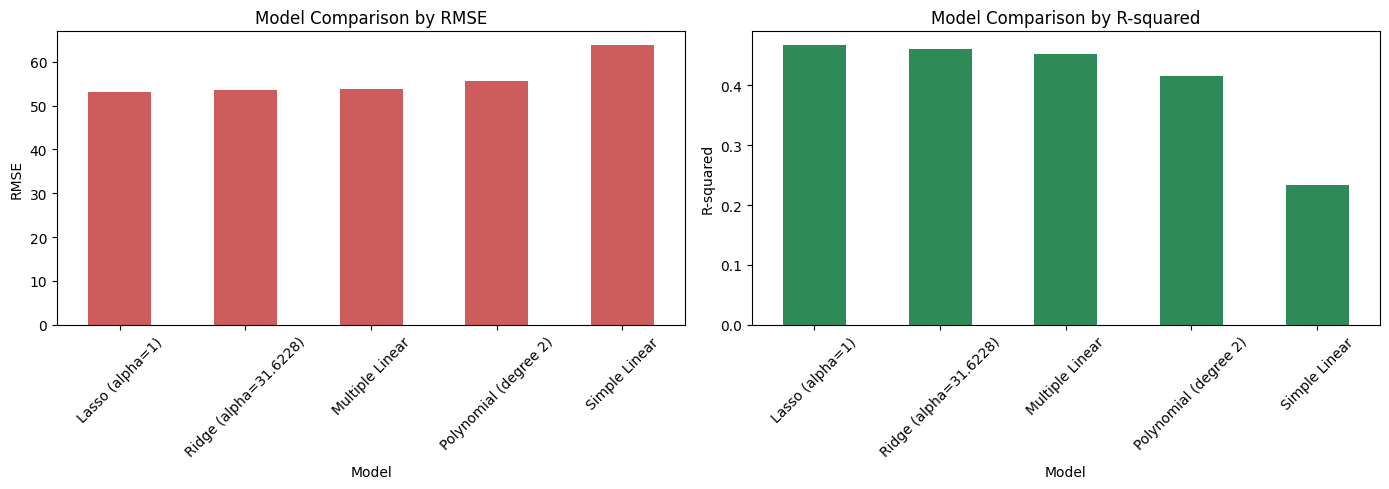

In [16]:
# show the final model comparison with plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
final_comparison['RMSE'].sort_values().plot(kind='bar', ax=axes[0], color='indianred')
axes[0].set_title('Model Comparison by RMSE')
axes[0].set_ylabel('RMSE')
axes[0].tick_params(axis='x', rotation=45)

final_comparison['R2'].sort_values(ascending=False).plot(kind='bar', ax=axes[1], color='seagreen')
axes[1].set_title('Model Comparison by R-squared')
axes[1].set_ylabel('R-squared')
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

### Overall findings

On this seeded 80/20 split, Lasso with alpha 1 has the lowest test RMSE (53.15) and highest test R-squared (0.4669). Ridge with cross-validated alpha 31.6228 is close (RMSE 53.49, R-squared 0.4599), while multiple linear regression reaches RMSE 53.85 and R-squared 0.4526. The degree-2 polynomial model is weaker than the multiple linear model, and the simple BMI-only model performs worst among these primary models.

Degree 3 has training R-squared 0.8773 but test R-squared -14.5613 and RMSE 287.13, indicating severe overfitting. These results show that added model complexity does not guarantee better generalization, and the selected regularization strength matters: very large alpha values degrade cross-validation performance. Cross-validation selected alpha using training data; the test set was reserved for this final comparison. Feature relationships describe predictive associations, not medical causation.